# D1 · Purchasing patterns at the training cutoff

How large is a typical basket and how often do customers buy the same product again? Run the notebook in order on CPU. It describes eligible baskets completed from **1 December 2010 through 30 September 2011** using the cancellation information available before 1 October. It writes four CSV tables, a JSON summary and three figures to `results/training_eda/`. [D1 cleaning](project2_colab.ipynb) · [Research plan, §2](../docs/CS5481_Project2_Research_Development_Plan_3.4.en.md) · [UCI Online Retail, Chen (2015), CC BY 4.0](https://doi.org/10.24432/C5BW33)

# D1 · 训练截止时点的购买模式

一张购物篮通常包含几种商品？客户多常再次购买同一种商品？选择 CPU，按顺序运行本 notebook。样本是 **2010 年 12 月 1 日至 2011 年 9 月 30 日**完成的有效购物篮，按 10 月 1 日前已知的冲销情况计算。四份 CSV 统计表、一份 JSON 摘要和三张图保存到 `results/training_eda/`。[D1 清洗](project2_colab.ipynb) · [研究计划第 2 节](../docs/CS5481_Project2_Research_Development_Plan_3.4.md) · [UCI Online Retail，Chen（2015），CC BY 4.0](https://doi.org/10.24432/C5BW33)

## Open the training snapshot

In Colab, authorize Drive access. The default project folder is `My Drive/CS5481_Project2_OnlineRetail`. The notebook reads `training_purchase_lines.csv.gz` and `training_basket_events.csv.gz` in `data/processed/` and checks both SHA-256 digests against `results/data_manifest.json`. If these inputs are incomplete, Colab downloads the three files from D1 revision `ccdbe06e` into the temporary runtime. The EDA results go to your Drive project. Locally, use a checkout containing the outputs of the D1 cleaning step.

## 读取训练截止时点的快照

在 Colab 授权挂载 Drive。默认项目文件夹为 `我的云端硬盘/CS5481_Project2_OnlineRetail`。从 `data/processed/` 读取 `training_purchase_lines.csv.gz` 和 `training_basket_events.csv.gz`，分别按 `results/data_manifest.json` 核对 SHA-256。若三份输入不齐，Colab 会将 D1 版本 `ccdbe06e` 的文件下载到临时运行环境，分析结果仍写入 Drive 项目文件夹。本地运行时，使用已生成 D1 清洗产物的仓库。

In [1]:
from pathlib import Path
import hashlib
import json
from tempfile import TemporaryDirectory
from urllib.error import URLError
from urllib.request import urlretrieve
import pandas as pd
from IPython.display import Image, display

TRAIN_START = pd.Timestamp("2010-12-01")
TRAIN_END = pd.Timestamp("2011-10-01")


EVENT_PATH = "data/processed/training_basket_events.csv.gz"
LINE_PATH = "data/processed/training_purchase_lines.csv.gz"
MANIFEST_PATH = "results/data_manifest.json"


def load_training_inputs(project):
    """Load the D1 snapshot that uses only credits observed before the training cutoff."""
    manifest = json.loads((project / MANIFEST_PATH).read_text(encoding="utf-8"))
    input_hashes = {}
    if not {EVENT_PATH, LINE_PATH}.issubset(manifest["outputs"]):
        raise ValueError("Regenerate the D1 cutoff-specific training snapshot and its manifest.")
    snapshot = manifest["training_snapshot"]
    if (pd.Timestamp(snapshot["start_inclusive"]) != TRAIN_START
            or pd.Timestamp(snapshot["end_exclusive"]) != TRAIN_END
            or pd.Timestamp(snapshot["credit_time_end_exclusive"]) != TRAIN_END):
        raise ValueError("The D1 snapshot uses a different basket or credit time window.")
    for relative in (EVENT_PATH, LINE_PATH):
        with (project / relative).open("rb") as stream:
            digest = hashlib.file_digest(stream, "sha256").hexdigest()
        if digest != manifest["outputs"][relative]["sha256"]:
            raise ValueError(f"File differs from its D1 cleaning manifest: {relative}")
        input_hashes[relative] = digest
    identifiers = {"CustomerID": "string", "InvoiceNo": "string", "StockCode": "string"}
    events = pd.read_csv(project / EVENT_PATH, dtype=identifiers, keep_default_na=False,
                         parse_dates=["basket_time"])
    lines = pd.read_csv(project / LINE_PATH, dtype=identifiers, keep_default_na=False,
                        usecols=["ExcelRow", *identifiers, "InvoiceDate", "Quantity", "UnitPrice",
                                 "original_quantity", "cancelled_units", "returned_units"],
                        parse_dates=["InvoiceDate"])
    return events, lines, input_hashes

In [2]:
try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is None:
    project = Path("..") if Path.cwd().name == "notebooks" else Path(".")
else:
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/CS5481_Project2_OnlineRetail")
    if not project.is_dir():
        selected = input(f"Drive project folder / Drive 项目文件夹 [Enter = {project}]：").strip()
        if selected:
            project = Path(selected)
            if not project.is_absolute() or not project.is_dir():
                raise ValueError("Choose an existing Drive project folder / 请选择已有项目文件夹")

def notebook_inputs(project, allow_download):
    paths = (MANIFEST_PATH, EVENT_PATH, LINE_PATH)
    if all((project / path).is_file() for path in paths):
        print("D1 data / D1 数据源：", project)
        return load_training_inputs(project)
    if not allow_download:
        raise FileNotFoundError("Run the D1 cleaning notebook or python -m scripts.prepare_data first. / 请先完成 D1 清洗。")
    revision = "ccdbe06ef24b831c2e8017b57bbba04d17192821"
    base = f"https://raw.githubusercontent.com/NobunagaK/online-retail-top10-recommendation/{revision}"
    print("D1 data from GitHub / 从 GitHub 读取固定版本：", revision)
    with TemporaryDirectory() as work:
        cached = Path(work)
        for relative in paths:
            dest = cached / relative
            dest.parent.mkdir(parents=True, exist_ok=True)
            try:
                urlretrieve(f"{base}/{relative}", dest)
            except URLError as exc:
                raise RuntimeError("Download failed. Run D1 cleaning in this Drive folder and retry. / 下载失败，请在此 Drive 文件夹运行 D1 清洗后重试。") from exc
        return load_training_inputs(cached)

all_events, all_lines, input_hashes = notebook_inputs(project, allow_download=drive is not None)
output_dir = project / "results/training_eda"
print("Results / 结果目录：", output_dir)

D1 data / D1 数据源： .


Results / 结果目录： results/training_eda


## Count active purchases as of 1 October

D1 allocates eligible credits to sale lines using the customer's exact SKU and the available units. A credit classified as a cancellation reduces the original units effective at its timestamp. A return proxy leaves the purchase in history. These are operational classifications inferred from time, region and the available transactions. The basket keeps its original completion time. Use the cutoff-specific D1 export so later credits cannot revise this training window. Each future monthly query needs its own as-of history.

The checks below reconcile the surviving lines to basket-item events. The first example checks invoice 541431, where 74,215 units of SKU 23166 were fully offset by C541433 sixteen minutes later. The second displays surviving lines with the largest active quantities and any partial reductions. Monetary totals use the active units at each original sale price.

## 统计截至 10 月 1 日仍有效的购买

D1 根据客户、原始商品编码和可供冲减的件数，为符合条件的贷项行匹配销售明细。按规则判作取消的记录，自贷项时间起扣减原购买件数。判作退货的记录仍保留原购买事件。这是根据时间、地区与现有交易记录作出的业务判断。整篮保留原先的完成时间。这里使用训练截止快照，防止后续贷项回写历史。未来构造每个月的查询时仍需按该月截止时间生成快照。

下方将剩余明细与篮内商品事件逐项核对。第一个例子是发票 541431 的商品 23166，74,215 件在 16 分钟后由 C541433 全额冲销。随后展示剩余有效件数最大的明细，以及部分冲减的实例。金额按剩余有效件数乘以原销售单价计算。

In [3]:
INVOICE_KEYS = ["CustomerID", "InvoiceNo"]
def select_training_data(
    events: pd.DataFrame, purchase_lines: pd.DataFrame, start=TRAIN_START, end=TRAIN_END,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Select whole baskets in [start, end) and their retained purchase lines.

    The event table supplies one completion time per (CustomerID, InvoiceNo).
    A basket completed at the cutoff is excluded even if some lines are earlier.
    Inputs with credit adjustments must already reflect only information available
    at the requested cutoff. Filtering dates cannot undo a later credit.
    Read CSV identifiers as strings to preserve their original spelling and zeros.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start >= end:
        raise ValueError("The training start must be earlier than the end.")
    times = pd.to_datetime(events["basket_time"])
    selected = times.ge(start) & times.lt(end)
    train_events = events.loc[selected].copy()
    train_events["basket_time"] = times.loc[selected]
    train_events = train_events.sort_values(
        ["basket_time", *INVOICE_KEYS, "StockCode"], ignore_index=True,
    )
    baskets = train_events[[*INVOICE_KEYS, "basket_time"]].drop_duplicates()
    train_lines = purchase_lines.merge(
        baskets, on=INVOICE_KEYS, how="inner", validate="many_to_one", suffixes=("_source", ""),
    )
    if "basket_time_source" in train_lines:
        if not pd.to_datetime(train_lines.pop("basket_time_source")).eq(train_lines["basket_time"]).all():
            raise ValueError("Purchase lines and events disagree on their original basket completion time.")
    train_lines["InvoiceDate"] = pd.to_datetime(train_lines["InvoiceDate"])
    if train_lines["InvoiceDate"].gt(train_lines["basket_time"]).any():
        raise ValueError("A retained invoice line is dated after its basket's completion.")
    if len(train_lines) != train_events["source_lines"].sum():
        raise ValueError("Training basket source-line counts differ from the matched purchase lines.")
    return train_events, train_lines.sort_values("ExcelRow", ignore_index=True)


events, lines = select_training_data(all_events, all_lines)
assert events["basket_time"].ge(TRAIN_START).all() and events["basket_time"].lt(TRAIN_END).all()
assert events["source_lines"].sum() == len(lines)
assert events["quantity"].sum() == lines["Quantity"].sum()
import math
assert math.isclose(events["amount_gbp"].sum(), (lines["Quantity"] * lines["UnitPrice"]).sum(), abs_tol=1e-6, rel_tol=0)
display(pd.Series({
    "first_completed": events["basket_time"].min(), "last_completed": events["basket_time"].max(),
    "source_lines": len(lines), "basket_item_events": len(events),
    "baskets": len(events[INVOICE_KEYS].drop_duplicates()),
    "customers": events["CustomerID"].nunique(), "items": events["StockCode"].nunique(),
}).to_frame("training_window"))
assert len(events) == len(all_events) and len(lines) == len(all_lines)
assert (lines["Quantity"] == lines["original_quantity"] - lines["cancelled_units"]).all()
example = events["InvoiceNo"].eq("541431") & events["StockCode"].eq("23166")
assert not example.any()
print("541431 / 23166 active events at cutoff / 截止时有效事件数", int(example.sum()))
evidence_columns = ["ExcelRow", "CustomerID", "InvoiceNo", "StockCode", "InvoiceDate",
                    "original_quantity", "cancelled_units", "returned_units", "Quantity", "UnitPrice"]
display(lines.nlargest(3, "Quantity")[evidence_columns])
display(lines.loc[lines["cancelled_units"].gt(0), evidence_columns].head(3))

,training_window
first_completed,2010-12-01 08:26:00
last_completed,2011-09-30 15:52:00
source_lines,262067
basket_item_events,259676
baskets,13040
customers,3612
items,3499


541431 / 23166 active events at cutoff / 截止时有效事件数 0


,ExcelRow,CustomerID,InvoiceNo,StockCode,InvoiceDate,original_quantity,cancelled_units,returned_units,Quantity,UnitPrice
140699,206123,13135,554868,22197,2011-05-27 10:52:00,4300,0,0,4300,0.72
60294,97434,18087,544612,22053,2011-02-22 10:43:00,3906,0,0,3906,0.82
185447,270887,14609,560599,18007,2011-07-19 17:04:00,3186,0,0,3186,0.06


,ExcelRow,CustomerID,InvoiceNo,StockCode,InvoiceDate,original_quantity,cancelled_units,returned_units,Quantity,UnitPrice
260,272,13767,536395,21314,2010-12-01 10:47:00,8,1,0,7,2.10
286,298,17924,536397,35004B,2010-12-01 10:51:00,12,5,0,7,4.65
850,886,17897,536488,22960,2010-12-01 12:31:00,8,6,0,2,4.25


## How does purchasing activity change by month?

Count customers within each month of basket completion. A returning customer can appear in several months. Events, units and purchase amounts can be summed across months. The busiest month by baskets was **2011-09** (1,735); the largest event count was 39,116 in 2011-09, and the smallest was 19,393 in 2011-02.

## 每个月的交易量怎样变化？

按购物篮完成月份统计不同客户，同一位回头客可能出现在多个月份。事件、件数与购买金额可以跨月相加。**2011-09** 的购物篮最多（1,735 个）。事件最多的是 2011-09（39,116 次），最少的是 2011-02（19,393 次）。

In [4]:
def monthly_activity(train_events: pd.DataFrame, start=TRAIN_START, end=TRAIN_END) -> pd.DataFrame:
    """Summarize each calendar month, including empty months within [start, end).

    Each basket and all its item events belong to its completion month. Customer
    counts are monthly distinct customers. Amounts preserve sub-penny GBP.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start >= end:
        raise ValueError("The training start must be earlier than the end.")
    times = pd.to_datetime(train_events["basket_time"])
    selected = times.ge(start) & times.lt(end)
    events = train_events.loc[selected].assign(month=times.loc[selected].dt.to_period("M"))
    monthly = events.groupby("month").agg(
        active_customers=("CustomerID", "nunique"),
        basket_item_events=("StockCode", "size"),
        source_lines=("source_lines", "sum"),
        units=("quantity", "sum"),
        amount_gbp=("amount_gbp", "sum"),
    )
    baskets = events[["month", *INVOICE_KEYS]].drop_duplicates()
    monthly.insert(1, "baskets", baskets.groupby("month").size())
    months = pd.period_range(start, end - pd.Timedelta(nanoseconds=1), freq="M", name="month")
    monthly = monthly.reindex(months, fill_value=0)
    monthly.index = monthly.index.astype(str)
    return monthly.reset_index()
monthly = monthly_activity(events)
assert monthly["basket_item_events"].sum() == len(events)
assert monthly["source_lines"].sum() == len(lines)
display(monthly)

,month,active_customers,baskets,basket_item_events,source_lines,units,amount_gbp
0,2010-12,884,1390,25140,25499,308479,559985.070
1,2011-01,738,979,20633,20848,272876,482135.630
2,2011-02,756,988,19393,19600,264551,441536.870
3,2011-03,972,1308,26445,26697,345775,579180.250
4,2011-04,852,1133,22137,22292,290350,452204.561
5,2011-05,1054,1540,27739,27933,372301,658177.190
6,2011-06,988,1383,26552,26750,359394,609753.470
7,2011-07,945,1318,26130,26362,365636,589105.041
8,2011-08,933,1266,26391,26625,393749,629468.990
9,2011-09,1258,1735,39116,39461,541523,933544.731


## What does a typical purchase look like?

Every surviving source line contributes one original unit price and one active quantity. Every customer invoice contributes one basket size. Every customer contributes one history length, counting one event per distinct basket–SKU including later purchases of the same SKU. The median line price was £1.95 and the median active quantity was 6 units. The median basket contained 15 distinct products. Across customers the median history was 34 events, and the median basket count was 2. Percentiles use linear interpolation.

## 典型的一次购买是什么样？

每条保留的原始明细贡献一次原单价和一次剩余有效件数，每张客户发票贡献一个购物篮大小，每位客户贡献一个历史长度。同一篮中的同一商品计一次事件，后来再购买该商品仍计入历史。明细单价中位数为 £1.95，有效件数中位数为 6 件。每篮商品种数中位数为 15，每位客户的历史长度中位数为 34 次事件，购物篮数中位数为 2。分位数使用线性插值。

In [5]:
def distribution_tables(
    train_events: pd.DataFrame, train_lines: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return exact-value frequencies and summaries of five training distributions.

    Original unit price and surviving quantity are observed once per active
    source line, with no quantity weighting. Basket size counts distinct SKUs per completed customer invoice.
    History length counts basket-item events per customer across the full training
    window, including repeat purchases on later invoices. Basket frequency counts
    distinct completed invoices per customer in that same window. Quantiles use
    linear interpolation on the individual observations.
    """
    baskets = train_events.groupby(INVOICE_KEYS)["StockCode"].nunique()
    distributions = {
        "line_unit_price_gbp": (train_lines["UnitPrice"], "source line", "GBP per unit"),
        "line_quantity": (train_lines["Quantity"], "source line", "units"),
        "basket_distinct_skus": (baskets, "basket", "distinct SKUs"),
        "customer_history_events": (
            train_events.groupby("CustomerID").size(), "customer", "basket-item events",
        ),
        "customer_baskets": (
            baskets.groupby(level="CustomerID").size(), "customer", "baskets",
        ),
    }
    frequencies, summaries = [], []
    quantiles = {"p25": .25, "median": .5, "p75": .75, "p90": .90, "p95": .95, "p99": .99}
    for measure, (observations, observation_unit, value_unit) in distributions.items():
        counts = observations.value_counts().sort_index().rename_axis("value")
        frequencies.append(counts.rename("frequency").reset_index().assign(measure=measure))
        percentiles = observations.quantile(list(quantiles.values()))
        summaries.append({
            "measure": measure,
            "observation_unit": observation_unit,
            "value_unit": value_unit,
            "count": len(observations),
            "min": observations.min(),
            **{name: percentiles.loc[q] for name, q in quantiles.items()},
            "max": observations.max(),
            "mean": observations.mean(),
        })
    frequency_table = pd.concat(frequencies, ignore_index=True)[["measure", "value", "frequency"]]
    return frequency_table, pd.DataFrame(summaries)
frequency, distributions = distribution_tables(events, lines)
assert frequency.groupby("measure")["frequency"].sum().to_dict() == distributions.set_index("measure")["count"].to_dict()
display(distributions)
display(frequency.loc[frequency["measure"].eq("line_unit_price_gbp")].head())

,measure,observation_unit,value_unit,count,min,p25,median,p75,p90,p95,p99,max,mean
0,line_unit_price_gbp,source line,GBP per unit,262067,0.001,1.25,1.95,3.75,6.75,8.50,12.75,649.5,2.934224
1,line_quantity,source line,units,262067,1.000,2.00,6.00,12.00,24.00,48.00,144.00,4300.0,13.411204
2,basket_distinct_skus,basket,distinct SKUs,13040,1.000,6.00,15.00,26.00,43.00,57.00,93.61,418.0,19.913804
3,customer_history_events,customer,basket-item events,3612,1.000,15.00,34.00,79.00,161.90,248.35,501.56,4806.0,71.892580
4,customer_baskets,customer,baskets,3612,1.000,1.00,2.00,4.00,8.00,11.00,24.89,136.0,3.610188


,measure,value,frequency
0,line_unit_price_gbp,0.001,3
1,line_unit_price_gbp,0.040,39
2,line_unit_price_gbp,0.060,58
3,line_unit_price_gbp,0.070,6
4,line_unit_price_gbp,0.080,34


## Which products reach the most customers?

Rank exact StockCodes by the number of distinct customers purchasing them, then by ascending code when counts tie. The top 10% rounded up comprises **350 of 3,499 SKUs** and accounts for 121,124 of 259,676 events (46.64%). The leading item, 22423, reached 747 distinct customers. These figures describe purchases. Measuring popularity in recommendations requires model predictions.

## 哪些商品覆盖的购买客户最多？

按购买每个原始商品码的不同客户数降序排列，同值按商品码升序排列。热门组取前 10% 并向上取整，共 **3,499 种商品中的 350 种**，占 259,676 次事件中的 121,124 次（46.64%）。排名第一的商品 22423 有 747 位购买客户。这些结果描述实际购买的集中度，衡量推荐结果的热门偏好仍需要模型预测。

In [6]:
def _share(numerator: int, denominator: int) -> float | None:
    return numerator / denominator if denominator else None

item_key = ["CustomerID", "InvoiceNo", "StockCode"]
if events[[*item_key, "basket_time"]].isna().any().any():
    raise ValueError("Each basket-item event needs a customer, invoice, SKU and completion time.")
if events.duplicated(item_key).any():
    raise ValueError("Expected one event per customer, invoice and SKU.")

customers = int(events["CustomerID"].nunique())
popularity = (
    events.groupby("StockCode", as_index=False, sort=False, observed=True)
    .agg(purchasing_customers=("CustomerID", "nunique"), basket_item_events=("InvoiceNo", "size"))
    .sort_values(["purchasing_customers", "StockCode"], ascending=[False, True], ignore_index=True)
)
items = len(popularity)
# Integer ceiling gives exactly the leading 10% (rounded up), even with ties.
head_items = (items + 9) // 10
popularity.insert(0, "rank", range(1, items + 1))
popularity.insert(3, "customer_reach_share", popularity["purchasing_customers"] / customers)
popularity["is_head"] = popularity["rank"].le(head_items)
head = popularity.loc[popularity["is_head"]]
head_events = int(head["basket_item_events"].sum())
head_customers = int(events.loc[events["StockCode"].isin(head["StockCode"]), "CustomerID"].nunique())
display(popularity.head(10))
print("Top items / 热门商品数：", head_items)

,rank,StockCode,purchasing_customers,customer_reach_share,basket_item_events,is_head
0,1,22423,747,0.206811,1330,True
1,2,85123A,728,0.201550,1546,True
2,3,47566,646,0.178848,1200,True
3,4,21212,545,0.150886,806,True
4,5,22720,531,0.147010,867,True
5,6,84879,527,0.145903,990,True
6,7,85099B,517,0.143134,1184,True
7,8,22960,493,0.136489,701,True
8,9,22457,484,0.133998,733,True
9,10,23298,482,0.133444,790,True


Top items / 热门商品数： 350


## When does an event count as a repeat purchase?

For a given customer and SKU, compare each event with the earliest basket completion time in the training window. A later timestamp establishes a repeat. At identical first timestamps, the data establish no order. Customer 12540 bought SKU 85123A in July and again in September. Customer 12971 has two first entries for SKU 21448 at the same minute. Inspect both examples below. Purchases before the workbook begins are unknown.

## 什么时候算作一次复购？

对同一客户和同一商品，将每次事件与训练期首次购买的购物篮完成时间比较。严格更晚才算复购。如果两张发票的首次购买时间相同，就无法据此确定先后顺序。客户 12540 在 7 月和 9 月各买过一次 85123A；客户 12971 的两张发票则在同一分钟首次出现 21448。下方列出原始发票号供核对。工作簿开始以前的购买无法观察。

In [7]:
pair_key = ["CustomerID", "StockCode"]
pairs = events.groupby(pair_key, sort=False, observed=True)
observed_pairs = pairs.ngroups
possible_pairs = customers * items
# Two invoices at the same first completion time do not provide earlier
# history for one another. The unique event key makes any later match a
# different invoice for this customer and SKU.
repeat = events["basket_time"].gt(pairs["basket_time"].transform("min"))
repeat_events = int(repeat.sum())
repeat_pairs = len(events.loc[repeat, pair_key].drop_duplicates())
event_count = len(events)

summary = {
    "customers": customers,
    "items": items,
    "basket_item_events": event_count,
    "observed_customer_item_pairs": observed_pairs,
    "possible_customer_item_pairs": possible_pairs,
    "interaction_sparsity": 1 - observed_pairs / possible_pairs if possible_pairs else None,
    "repeat_purchase_events": repeat_events,
    "repeat_event_share": _share(repeat_events, event_count),
    "repeated_customer_item_pairs": repeat_pairs,
    "repeated_pair_share": _share(repeat_pairs, observed_pairs),
    "head_items": head_items,
    "head_purchase_events": head_events,
    "head_event_share": _share(head_events, event_count),
    "head_purchasing_customers": head_customers,
    "head_customer_reach_share": _share(head_customers, customers),
}
preferences = summary
display(pd.Series({
    "Repeat events / 复购事件": f"{repeat_events:,}",
    "All purchase events / 全部购买事件": f"{event_count:,}",
    "Repeat event share / 事件复购率": f"{preferences['repeat_event_share']:.2%}",
    "Repeated pairs / 发生复购的客户商品组合": f"{repeat_pairs:,}",
    "Observed pairs / 有购买记录的组合": f"{observed_pairs:,}",
    "Repeated pair share / 已购组合中发生复购的比例": f"{preferences['repeated_pair_share']:.2%}",
    "Possible pairs / 可能组合": f"{possible_pairs:,}",
    "Interaction sparsity / 稀疏度": f"{preferences['interaction_sparsity']:.2%}",
}).to_frame("training_value"))
trace = events.loc[
    (events["CustomerID"].eq("12540") & events["StockCode"].eq("85123A")) |
    (events["CustomerID"].eq("12971") & events["StockCode"].eq("21448")),
    ["CustomerID", "StockCode", "InvoiceNo", "basket_time", "quantity"],
].copy()
trace["strictly_later_repeat"] = repeat.loc[trace.index]
display(trace)

,training_value
Repeat events / 复购事件,"71,479"
All purchase events / 全部购买事件,"259,676"
Repeat event share / 事件复购率,27.53%
Repeated pairs / 发生复购的客户商品组合,"38,490"
Observed pairs / 有购买记录的组合,"188,190"
Repeated pair share / 已购组合中发生复购的比例,20.45%
Possible pairs / 可能组合,"12,638,388"
Interaction sparsity / 稀疏度,98.51%


,CustomerID,StockCode,InvoiceNo,basket_time,quantity,strictly_later_repeat
88129,12971,21448,547944,2011-03-28 14:59:00,12,False
88132,12971,21448,547946,2011-03-28 14:59:00,12,False
110299,12971,21448,550967,2011-04-21 16:58:00,12,True
188165,12540,85123A,561093,2011-07-25 10:01:00,12,False
247742,12540,85123A,568001,2011-09-23 11:35:00,12,True


## How frequent are repeats, and how sparse are the observations?

71,479 of 259,676 basket-item events (27.53%) follow an earlier purchase of the same SKU by the same customer. At the customer–SKU level, 38,490 of 188,190 observed pairs (20.45%) have a repeat. Subtracting distinct pairs from all events would add 7 events tied at the first timestamp. The 3,612 active customers and 3,499 observed SKUs give 12,638,388 possible pairs and **98.51% sparsity**. An unobserved pair means no qualifying purchase appears in this window.

## 复购有多常见？购买记录有多稀疏？

259,676 次篮内商品事件中，71,479 次能找到同一客户在严格更早时购买同一商品的记录（27.53%）。以客户–商品组合计算，在 188,190 个已购组合中，38,490 个出现复购（20.45%）。直接用总事件数减去不同组合数，会多算 7 个在首次购买时并列的事件。3,612 位活跃客户与 3,499 种已购商品构成 12,638,388 个可能组合，**稀疏度为 98.51%**。未观察到的组合表示该窗口中没有符合口径的购买记录。

## Draw the distributions from the exported counts

The monthly figure uses the monthly table. The distribution curves use the exact-value frequency table, including the extremes. The popularity figure uses the same sorted SKU list as the reported head count. Axis labels identify what is counted and in which units.

## 从统计表绘制结果图

月度图使用月度统计表；分布图使用各个取值的精确频数，包括极端值；商品热度图沿用热门组统计时的排序结果。每个坐标轴均注明所统计的对象或单位。

In [8]:
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, MaxNLocator
import pandas as pd


BLUE = "#245e85"
TEAL = "#137563"
INK = "#1f3544"


def _number(value, position=None):
    if abs(value) >= 1_000_000:
        return f"{value / 1_000_000:g}M"
    if abs(value) >= 1_000:
        return f"{value / 1_000:g}k"
    return f"{value:,.6f}".rstrip("0").rstrip(".")


def _heading(figure, title, subtitle):
    figure.text(0.075, 0.97, title, va="top", fontsize=17, fontweight="bold", color=INK)
    figure.text(0.075, 0.915, subtitle, va="top", fontsize=10, color=INK)


def _style(axis):
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["bottom", "left"]].set_color("#899aa3")
    axis.tick_params(labelsize=9, labelcolor=INK, color="#899aa3")
    axis.grid(axis="y", which="major", color="#dbe1e4", linewidth=0.7)
    axis.set_axisbelow(True)


def _monthly(monthly, window):
    figure = Figure(figsize=(11, 7))
    axes = figure.subplots(2, 2, sharex=True).flat
    figure.subplots_adjust(left=0.08, right=0.985, top=0.80, bottom=0.13, hspace=0.35, wspace=0.21)
    _heading(figure, "Monthly purchasing activity", f"{window}  ·  Month of basket completion")
    panels = [
        ("baskets", "Customer invoices (baskets)"),
        ("basket_item_events", "Distinct items summed across baskets (events)"),
        ("units", "Quantity purchased (units)"),
        ("amount_gbp", "Active purchase amount (GBP)"),
    ]
    month_labels = pd.PeriodIndex(monthly["month"], freq="M").strftime("%b\n%Y")
    for axis, (column, title) in zip(axes, panels):
        _style(axis)
        axis.bar(range(len(monthly)), monthly[column], color=BLUE, width=0.70)
        axis.set_title(title, fontsize=11, loc="left", color=INK)
        axis.set_ylim(bottom=0)
        axis.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=column != "amount_gbp"))
        axis.yaxis.set_major_formatter(FuncFormatter(_number))
        axis.set_xticks(range(len(monthly)), month_labels)
    return figure

In [9]:
def _distributions(distributions, window):
    figure = Figure(figsize=(12, 7.4))
    grid = figure.add_gridspec(2, 6, left=0.075, right=0.975, top=0.785,
                               bottom=0.09, wspace=0.78, hspace=0.52)
    _heading(figure, "Distribution of purchase lines, baskets and customer histories",
             f"{window}  ·  Share at or above each observed value  ·  Both axes logarithmic  ·  Full range")
    panels = [
        ("line_unit_price_gbp", "Unit price per purchase line", "GBP per unit", "Purchase lines (%)", grid[0, :3]),
        ("line_quantity", "Active units per purchase line", "Units", "Purchase lines (%)", grid[0, 3:]),
        ("basket_distinct_skus", "Size of a basket", "Distinct SKUs", "Baskets (%)", grid[1, :2]),
        ("customer_history_events", "Events per customer", "Basket-item events", "Customers (%)", grid[1, 2:4]),
        ("customer_baskets", "Baskets per customer", "Completed baskets", "Customers (%)", grid[1, 4:]),
    ]
    for measure, title, unit, population, slot in panels:
        axis = figure.add_subplot(slot)
        _style(axis)
        axis.set_title(title, fontsize=11, loc="left", color=INK)
        axis.set_xlabel(unit, fontsize=10)
        axis.set_ylabel(population, fontsize=10)
        rows = distributions.loc[distributions["measure"] == measure].sort_values("value")
        if rows.empty:
            axis.text(0.5, 0.5, "No observations", transform=axis.transAxes, ha="center")
            continue
        # For an observed x, sum exact frequencies from x through the maximum.
        share = rows["frequency"].iloc[::-1].cumsum().iloc[::-1] * 100 / rows["frequency"].sum()
        axis.step(rows["value"], share, where="pre", color=TEAL, linewidth=1.8)
        axis.scatter(rows["value"].iloc[[0, -1]], share.iloc[[0, -1]], s=16, color=TEAL, zorder=3)
        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.minorticks_off()
        axis.yaxis.set_major_formatter(FuncFormatter(_number))
        axis.xaxis.set_major_formatter(FuncFormatter(_number))
    return figure

In [10]:
def _popularity(popularity, window):
    figure = Figure(figsize=(10.5, 6))
    axis = figure.subplots()
    figure.subplots_adjust(left=0.10, right=0.975, top=0.80, bottom=0.14)
    _heading(figure, "Item popularity by customer reach",
             f"{window}  ·  All {len(popularity):,} training SKUs  ·  Logarithmic customer count")
    _style(axis)
    axis.set_xlabel("Item rank by number of distinct purchasing customers")
    axis.set_ylabel("Distinct customers purchasing the item")
    if not popularity.empty:
        ordered = popularity.sort_values("rank")
        head = ordered.loc[ordered["is_head"], "rank"]
        if not head.empty:
            axis.axvspan(0.5, head.max() + 0.5, color=TEAL, alpha=0.13,
                         label=f"Top 10% of items (ranks 1–{head.max():,})")
            axis.legend(loc="upper right", frameon=False, fontsize=10)
        axis.plot(ordered["rank"], ordered["purchasing_customers"], color=BLUE, linewidth=2)
        axis.set_yscale("log")
        axis.set_xlim(0.5, ordered["rank"].max() + 0.5)
        axis.minorticks_off()
    axis.yaxis.set_major_formatter(FuncFormatter(_number))
    axis.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
    return figure


def build_training_figures(tables: dict[str, pd.DataFrame]) -> dict[str, Figure]:
    """Build displayable, unsaved figures. The caller chooses file format and DPI."""
    monthly = tables["monthly_activity"].sort_values("month")
    periods = pd.PeriodIndex(monthly["month"], freq="M")
    window = "Training window"
    if len(periods):
        window += f" · {periods.min().strftime('%b %Y')}–{periods.max().strftime('%b %Y')}"
    return {
        "monthly_volume": _monthly(monthly, window),
        "size_distributions": _distributions(tables["distributions"], window),
        "item_popularity": _popularity(tables["item_popularity"], window),
    }

## Export the tables, figures and summary

The JSON summary records the interval, input file hashes, numerators, denominators and metric definitions. CSVs contain the ten monthly rows, exact frequencies, distribution summary and ranked SKU table. Each PNG can be used in the report. The CLI reproduces these same outputs with `python -m scripts.analyze_training`.

## 保存表格、图片与统计摘要

JSON 摘要记录日期边界、输入文件校验值、各指标的分子分母和定义。四份 CSV 依次保存月度活动、精确取值频数、分布分位数和商品热度排名。三张 PNG 图可直接用于报告。本地命令 `python -m scripts.analyze_training` 可复现相同的结果。

In [11]:
def summarize_window(train_events, train_lines, preferences, input_hashes):
    return {
        "window": {"field": "basket_time", "start_inclusive": TRAIN_START.isoformat(),
                   "end_exclusive": TRAIN_END.isoformat()},
        "input_sha256": input_hashes,
        "source_lines": len(train_lines),
        "baskets": len(train_events[["CustomerID", "InvoiceNo"]].drop_duplicates()),
        "units": int(train_events["quantity"].sum()),
        "recorded_amount_gbp": float(format(train_events["amount_gbp"].sum(), ".15g")),
        **preferences,
        "definitions": {
            "source_lines": "Positive sale lines with units still active at the exclusive training cutoff. Fully offset lines are absent.",
            "units": "Original sale units less quantities allocated to cancellation proxies observed before the cutoff. Return proxies preserve purchase units.",
            "recorded_amount_gbp": "Surviving units multiplied by the original sale line price, summed over active training purchases.",
            "repeat_event_share": "Basket-item events with an earlier completed basket for the same customer and SKU / all training basket-item events. Equal timestamps provide no earlier history.",
            "repeated_pair_share": "Observed customer-SKU pairs with a strictly later purchase / all observed training customer-SKU pairs.",
            "interaction_sparsity": "1 - observed distinct customer-SKU pairs / (active customers x observed SKUs).",
            "head_items": "Ceiling of 10% of observed SKUs, ranked by distinct customers descending, then exact StockCode ascending.",
            "head_event_share": "Events for head SKUs / all training events.",
            "head_customer_reach_share": "Distinct customers with any head SKU / distinct active training customers.",
        },
    }


def save_training_eda(output_dir, tables, summary, figures):
    """Stage the tables and figures together and replace the summary last."""
    output_dir.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=output_dir) as dirname:
        staged = Path(dirname)
        paths = []
        for name, table in tables.items():
            path = staged / f"{name}.csv"
            table.to_csv(path, index=False, float_format="%.15g")
            paths.append(path)
        for name, figure in figures.items():
            path = staged / f"{name}.png"
            figure.savefig(path, format="png", dpi=170, bbox_inches="tight", facecolor="white")
            paths.append(path)
        summary_path = staged / "summary.json"
        summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False) + "\n",
                                encoding="utf-8")
        for path in [*paths, summary_path]:
            path.replace(output_dir / path.name)


tables = {"monthly_activity": monthly, "distributions": frequency, "distribution_summary": distributions,
          "item_popularity": popularity}
summary = summarize_window(events, lines, preferences, input_hashes)
figures = build_training_figures(tables)
save_training_eda(output_dir, tables, summary, figures)
print("Saved under / 保存目录：", output_dir)

Saved under / 保存目录： results/training_eda


### Monthly activity

Read each panel on its own vertical scale. Distinct customer counts by month are included in the CSV.

### 月度活动

各面板的纵轴单位不同。逐月活跃客户数可在月度 CSV 中查看。

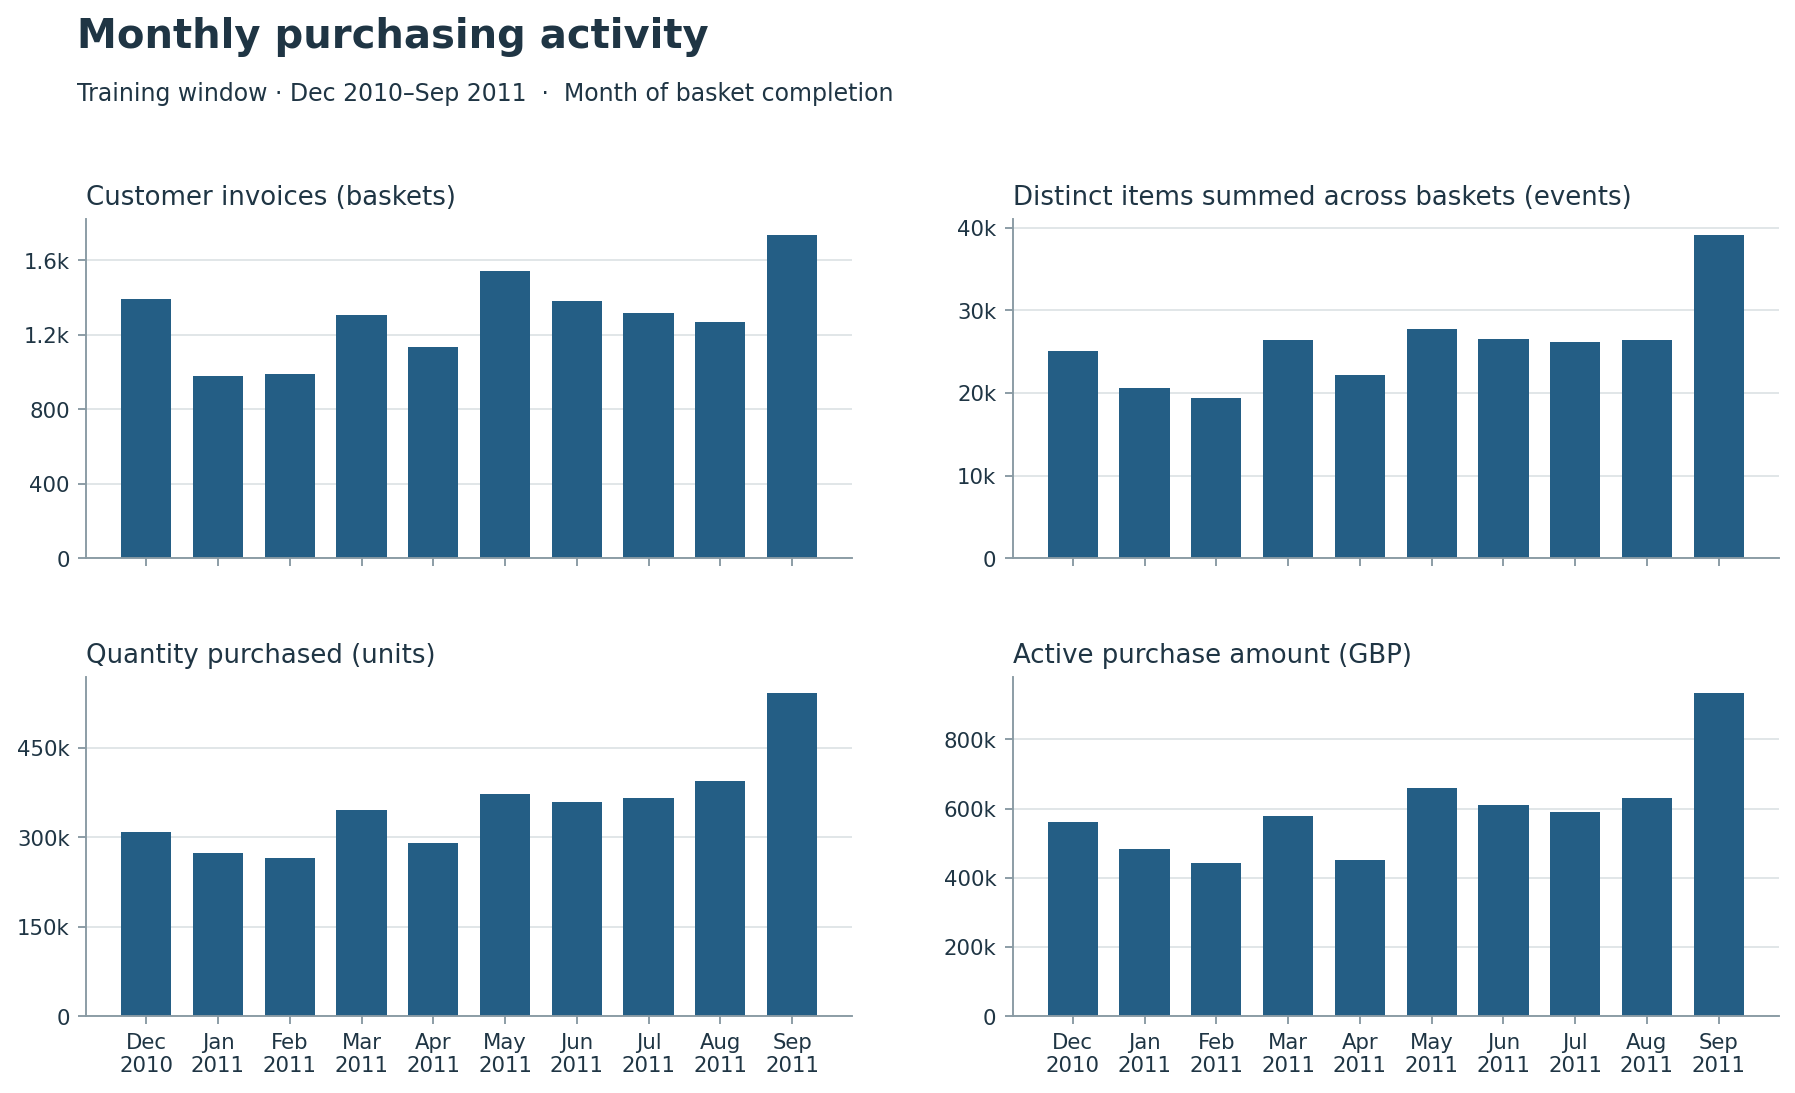

In [12]:
display(Image(filename=str(output_dir / "monthly_volume.png"), width=920))

### Size and price distributions

At each value x, the vertical axis shows the percentage of observations at or above x. Both axes are logarithmic. After cancellation adjustments, the largest surviving purchase line contains **4,300 units**, while the lowest surviving line price is £0.001.

### 规模与价格分布

横轴的每个 x 对应观测值大于等于 x 的百分比，两轴均为对数刻度。处理截止前的取消后，剩余明细的最大有效件数为 **4,300 件**，保留明细中的最低单价为 £0.001。

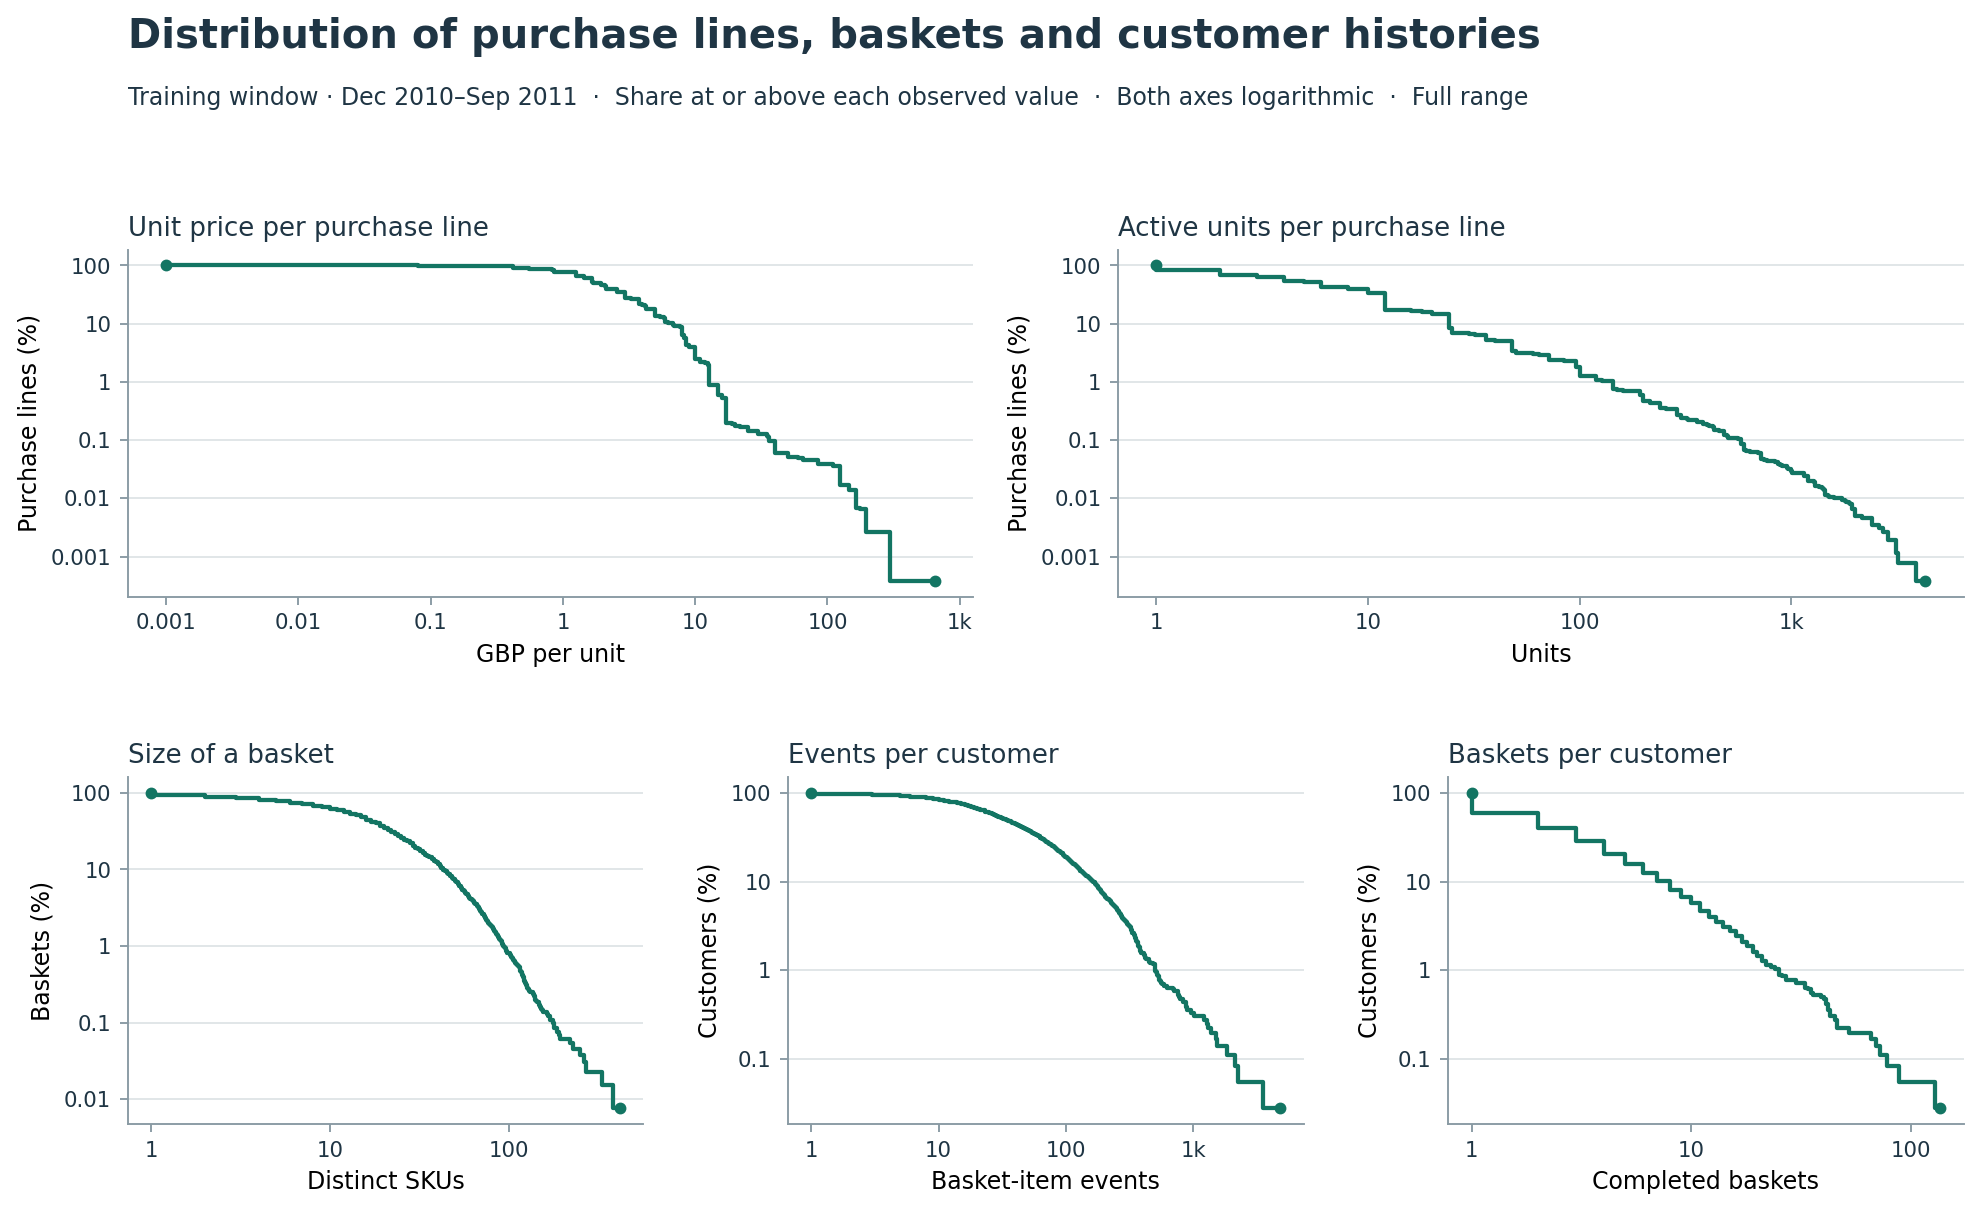

In [13]:
display(Image(filename=str(output_dir / "size_distributions.png"), width=920))

### Item popularity across the catalog

Each point represents one ranked SKU. The vertical axis is the number of distinct buyers on a log scale. Shading identifies ranks 1–350.

### 目录内商品的热度

每个排名位置对应一种商品，纵轴是对数刻度的不同购买客户数。阴影覆盖第 1 至 350 名。

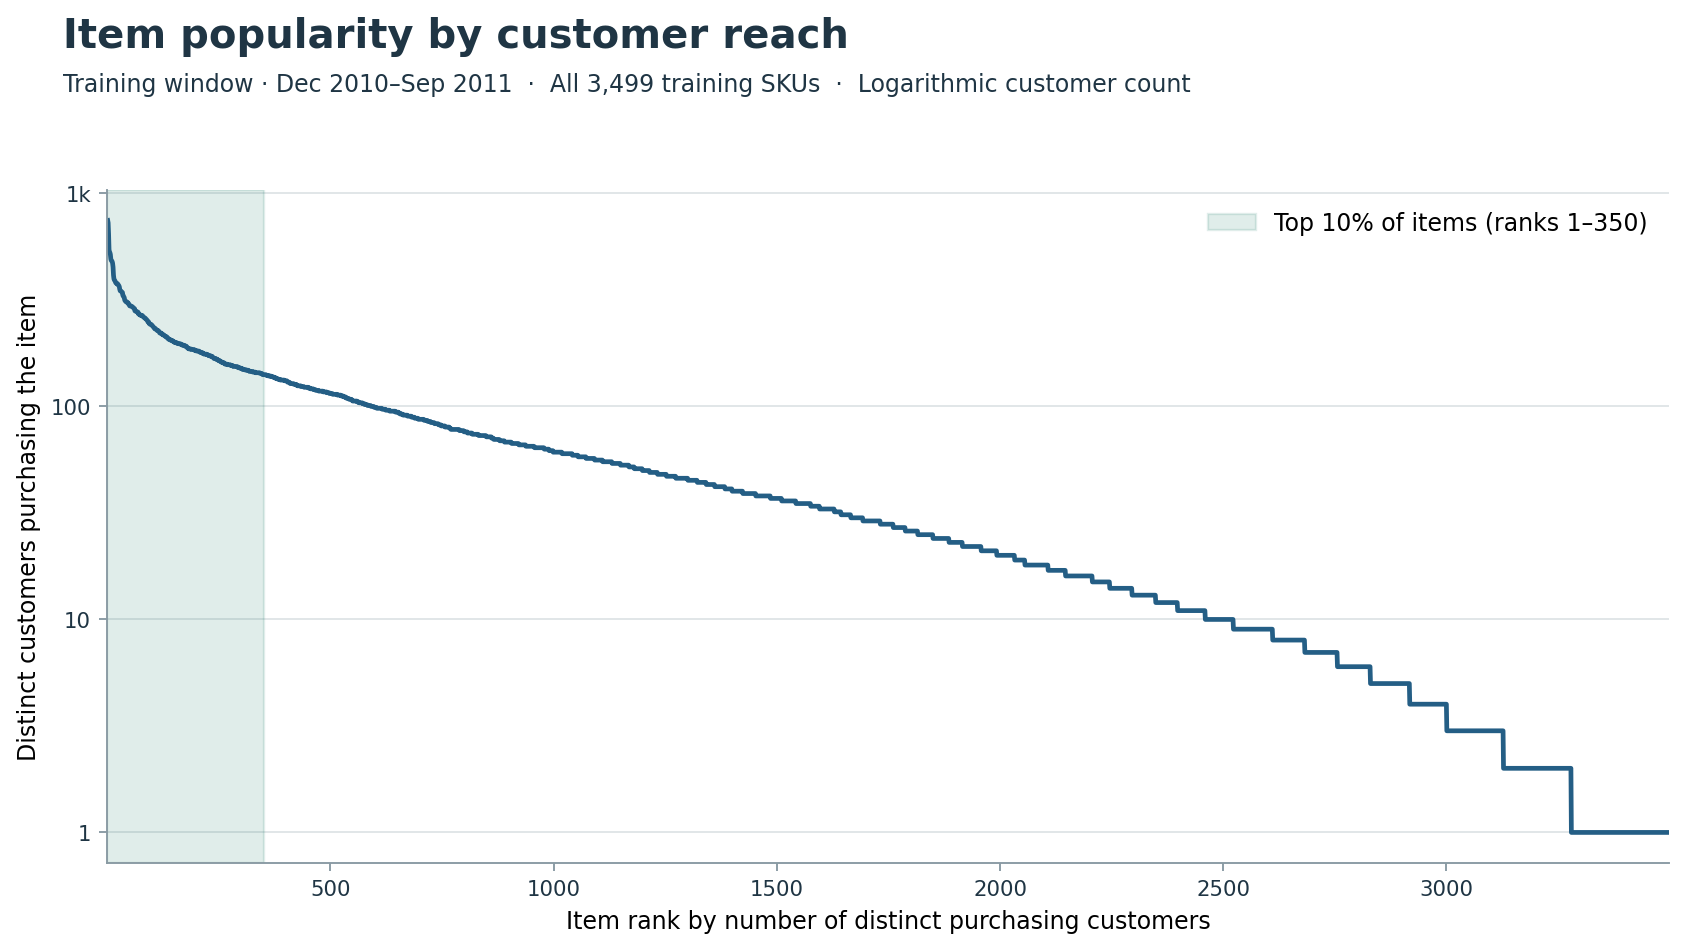

In [14]:
display(Image(filename=str(output_dir / "item_popularity.png"), width=920))